In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from keras.models import Sequential
from keras.layers import Dense
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
import matplotlib.pyplot as plt

# Load your dataset
data = pd.read_csv('2yr_raw.txt', delimiter=',')
#data1 = pd.read_excel('Michael_Model_RUN-6-7.xlsx', sheet_name='2Lines-fake_Training_data')
#data = data.append(data1)
data['TM_STAMP'] = (pd.to_datetime(data['TM_STAMP']).astype('int64') // 10**9)
# Now replace NaN values with 0
#data['DIGITS'].fillna(-99, inplace=True)

#data['AMP'].fillna(-9, inplace=True)
data=data.dropna()

In [2]:
data

,Unnamed: 0,ID_PIEZO,TM_STAMP,DIGITS,AMP,SIG2NOISE,REPORTABLE
0,0,392,1609459200,8679.682617,3.000000,580.325806,True
1,1,392,1609462800,8679.713867,3.000000,536.404236,True
2,2,392,1609466400,8679.676758,3.000000,758.372925,True
3,3,392,1609470000,8679.657227,3.000000,615.265381,True
4,4,392,1609473600,8679.676758,3.000000,718.530701,True
...,...,...,...,...,...,...,...
22345305,22345305,2561,1640998800,8743.775391,2.433574,4637.093750,True
22345306,22345306,2560,1640995200,8916.651367,2.960516,1025.008545,True
22345307,22345307,2560,1640998800,8916.620117,2.958723,861.051147,True
22345308,22345308,2559,1640995200,8985.988281,2.515944,1071.302979,True


In [3]:
data = data[['ID_PIEZO','DIGITS','AMP','REPORTABLE']]

In [4]:
# Convert 'Color' column to categorical
data['ID_PIEZO'] = data['ID_PIEZO'].astype('category')

C:\Users\Michael.Tetteh\AppData\Local\Temp\ipykernel_17344\2773880730.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['ID_PIEZO'] = data['ID_PIEZO'].astype('category')


In [5]:
def one_hot_encoder(dataset):
    # Initialize a LabelEncoder object
    label_encoder = LabelEncoder()

    # Iterate over each column in the dataset
    for column in dataset.columns:
        # Check if the column data type is 'object' (categorical)
        if dataset[column].dtype == np.object:
            # Fit and transform the column with LabelEncoder
            encoded_labels = label_encoder.fit_transform(dataset[column])
            # Create a one-hot encoding representation
            one_hot = np.eye(len(label_encoder.classes_))[encoded_labels]
            # Replace the original column with the one-hot encoded representation
            dataset[column] = one_hot

    return dataset

In [6]:
# Apply one-hot encoding
one_hot_encoded_dataset = one_hot_encoder(data)

C:\Users\Michael.Tetteh\AppData\Local\Temp\ipykernel_17344\1314139802.py:8: DeprecationWarning: `np.object` is a deprecated alias for the builtin `object`. To silence this warning, use `object` by itself. Doing this will not modify any behavior and is safe. 
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  if dataset[column].dtype == np.object:


In [7]:
# Split the dataset into input features and target variable
X = one_hot_encoded_dataset.drop('REPORTABLE', axis=1)
y = one_hot_encoded_dataset['REPORTABLE']

In [8]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [9]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
#X = scaler.fit_transform(X)

In [10]:
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [11]:
# Define the neural network model
model = Sequential()
model.add(Dense(128, activation='relu', input_dim=X_train.shape[1]))
model.add(Dense(128, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

In [12]:
# Compile the model
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

In [13]:
# Train the model
model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10, batch_size=512, verbose=1)

Epoch 1/10
32415/32415 [==============================] - 111s 3ms/step - loss: 0.0103 - accuracy: 0.9979 - val_loss: 20822920003584.0000 - val_accuracy: 0.9988
Epoch 2/10
32415/32415 [==============================] - 108s 3ms/step - loss: 0.0055 - accuracy: 0.9988 - val_loss: 0.0052 - val_accuracy: 0.9988
Epoch 3/10
32415/32415 [==============================] - 103s 3ms/step - loss: 0.0045 - accuracy: 0.9990 - val_loss: 0.0044 - val_accuracy: 0.9989
Epoch 4/10
32415/32415 [==============================] - 106s 3ms/step - loss: 0.0040 - accuracy: 0.9991 - val_loss: 0.0036 - val_accuracy: 0.9991
Epoch 5/10
32415/32415 [==============================] - 103s 3ms/step - loss: 0.0037 - accuracy: 0.9991 - val_loss: 0.0033 - val_accuracy: 0.9992
Epoch 6/10
32415/32415 [==============================] - 101s 3ms/step - loss: 0.0034 - accuracy: 0.9992 - val_loss: 0.0030 - val_accuracy: 0.9994
Epoch 7/10
32415/32415 [==============================] - 103s 3ms/step - loss: 0.0032 - accuracy: 

In [18]:
val = pd.read_csv('Q1_raw.txt', delimiter=',')
val['TM_STAMP'] = (pd.to_datetime(val['TM_STAMP']).astype('int64') // 10**9)
#val['DIGITS'].fillna(-99, inplace=True)

#val['AMP'].fillna(-9, inplace=True)
val=val.dropna()
val= val[['ID_PIEZO','DIGITS','AMP','REPORTABLE']]

In [19]:
one_hot_encoded_dataset1 = one_hot_encoder(val)

C:\Users\Michael.Tetteh\AppData\Local\Temp\ipykernel_17344\1314139802.py:8: DeprecationWarning: `np.object` is a deprecated alias for the builtin `object`. To silence this warning, use `object` by itself. Doing this will not modify any behavior and is safe. 
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  if dataset[column].dtype == np.object:


In [20]:
# Split the dataset into input features and target variable
val_x1 = one_hot_encoded_dataset1.drop('REPORTABLE', axis=1)
val_y1 = one_hot_encoded_dataset1['REPORTABLE']

In [21]:
val_x1 = scaler.transform(val_x1)

In [22]:
# Evaluate the model on the test set
loss, accuracy = model.evaluate(val_x1, val_y1, verbose=0)
print(f'Test Loss: {loss:.4f}')
print(f'Test Accuracy: {accuracy:.4f}')

Test Loss: 0.0159
Test Accuracy: 0.9962


In [23]:
pre_val= model.predict(val_x1)
pre_val

71232/71232 [==============================] - 90s 1ms/step


array([[1.],
       [1.],
       [1.],
       ...,
       [1.],
       [1.],
       [1.]], dtype=float32)

In [24]:
for i in range(len(pre_val)):
    if pre_val[i] >= 0.5:
        pre_val[i] = 1
    else:
        pre_val[i] = 0

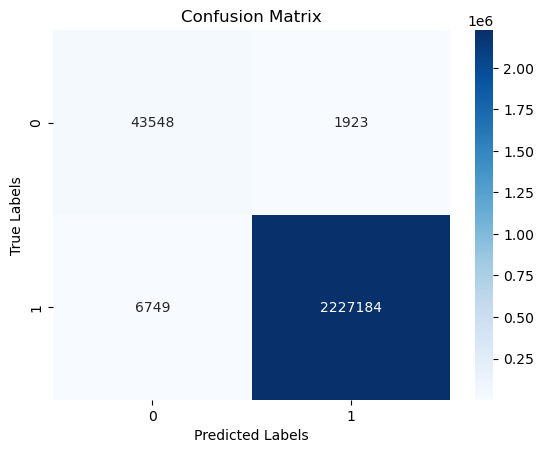

In [25]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
cm = confusion_matrix(val_y1, pre_val)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

In [27]:
# Add the predictions to the new dataset
val['PREDICTIONS'] = pre_val

#val['TM_STAMP'] = pd.to_datetime(val['TM_STAMP'], unit='s')
val

,ID_PIEZO,DIGITS,AMP,REPORTABLE,PREDICTIONS
0,1109,8584.845703,2.8750,True,1.0
1,1109,8584.845703,2.8750,True,1.0
2,1109,8584.852539,2.8750,True,1.0
3,1109,8584.845703,2.8750,True,1.0
4,1101,8789.166016,2.6875,True,1.0
...,...,...,...,...,...
2428837,1182,8937.125977,2.3125,True,1.0
2428840,1182,8937.468750,2.3125,True,1.0
2428842,1182,8937.841797,2.3125,True,1.0
2428843,1182,8937.884766,2.3125,True,1.0


In [28]:
val['REPORTABLE'] =val['REPORTABLE'].astype('float')

In [39]:
val1 = pd.read_csv('Q1_raw.txt', delimiter=',')
#val['TM_STAMP'] = (pd.to_datetime(val['TM_STAMP']).astype('int64') // 10**9)
#val['DIGITS'].fillna(-99, inplace=True)

#val['AMP'].fillna(-9, inplace=True)
val1=val1.dropna()
val1= val1[['ID_PIEZO','TM_STAMP','DIGITS','AMP','REPORTABLE']]
val1['TM_STAMP'] = pd.to_datetime(val1['TM_STAMP'], unit='s')
val1

ValueError: non convertible value 2023-01-01 01:00:00 with the unit 's'

In [35]:
# Add the predictions to the new dataset
val1['PREDICTIONS'] = pre_val

In [36]:
import pandas as pd
from sklearn.metrics import confusion_matrix

# Assuming you already have the new_data dataframe
# Step 2: Create a new column to store the comparison results
val1['COMPARE'] = val1['REPORTABLE'] == (val1['PREDICTIONS'] == 1)

# Get unique ID_PIEZO values for predicted false and actual REPORTABLE false
predicted_false = val.loc[val['PREDICTIONS'] == 0, 'ID_PIEZO'].unique()
actual_reportable_false = val.loc[val['REPORTABLE'] == False, 'ID_PIEZO'].unique()

# Save the unique ID_PIEZO's for predicted false and actual REPORTABLE false in separate text files
with open("PIEZO_Predicted_False.txt", 'w') as f:
    for id_piezo in predicted_false:
        f.write(str(id_piezo) + '\n')

with open("Actual_Piezo_Reportable_False.txt", 'w') as f:
    for id_piezo in actual_reportable_false:
        f.write(str(id_piezo) + '\n')

# Step 4: Create a confusion matrix
y_true = val['REPORTABLE']
y_pred = val['PREDICTIONS'].apply(lambda x: x == 1)  # Convert 1's and 0's to boolean values
cm = confusion_matrix(y_true, y_pred)

# Create a labeled confusion matrix using a Pandas DataFrame
labeled_cm = pd.DataFrame(cm, index=['Actual: False', 'Actual: True'], columns=['Predicted: False', 'Predicted: True'])

print("Confusion Matrix:")

Confusion Matrix:


In [37]:
# importing os module
# Directory
import shutil
import os
directory = "ML_FIGURES"

 

dir ="C:/Temp/ML_FIGURES_14"
if os.path.exists(dir):
    shutil.rmtree(dir)
os.makedirs(dir)

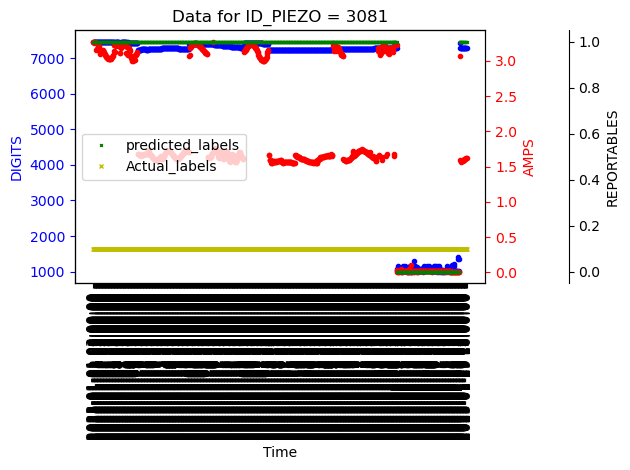

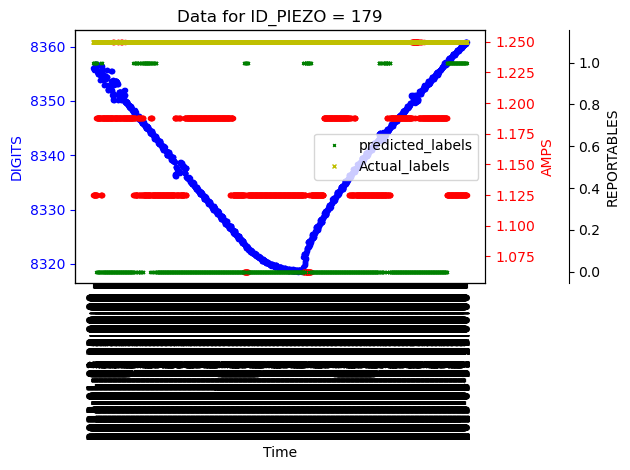

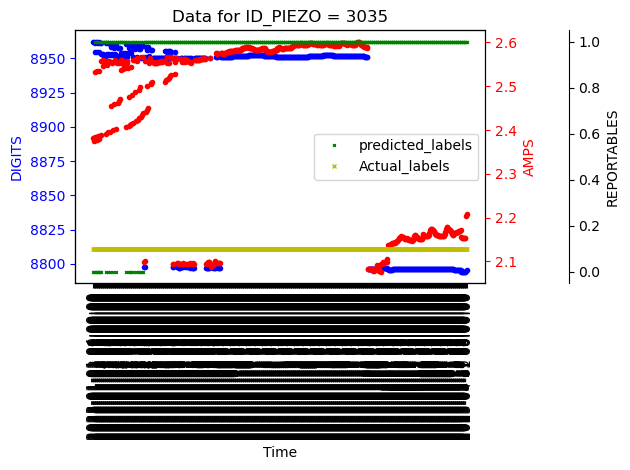

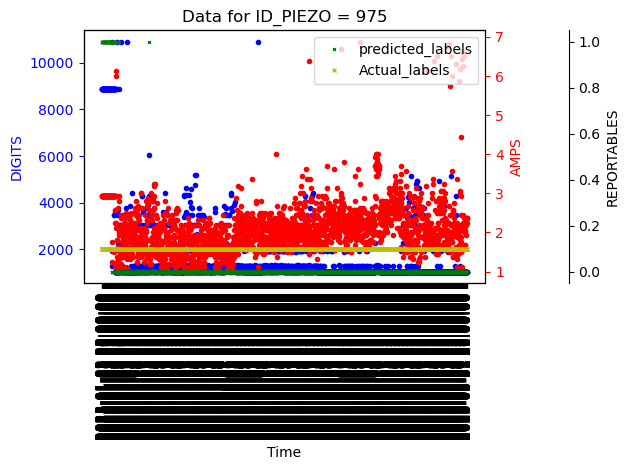

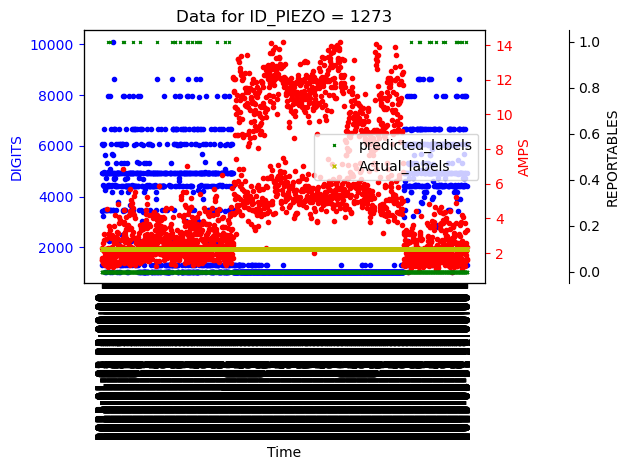

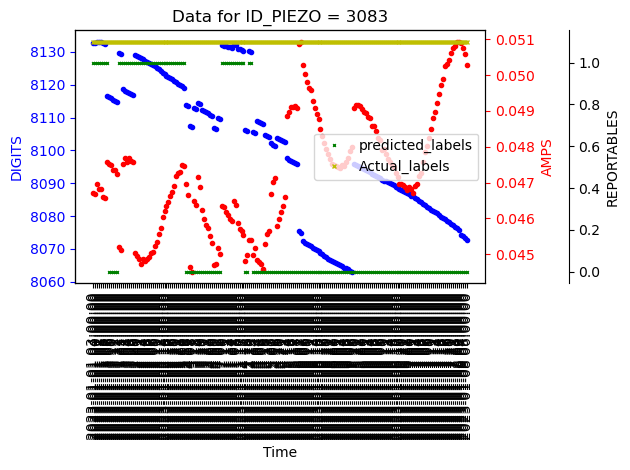

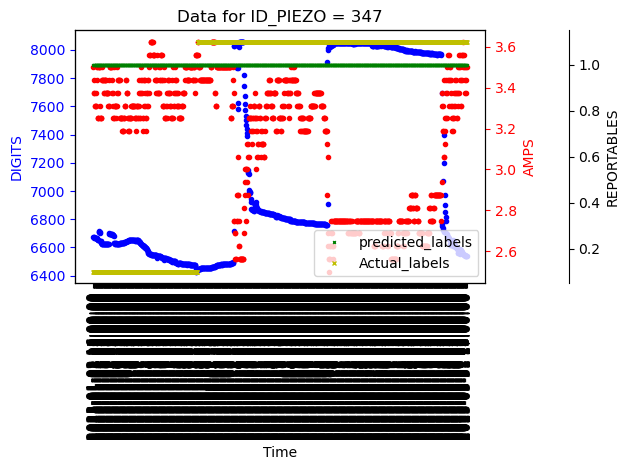

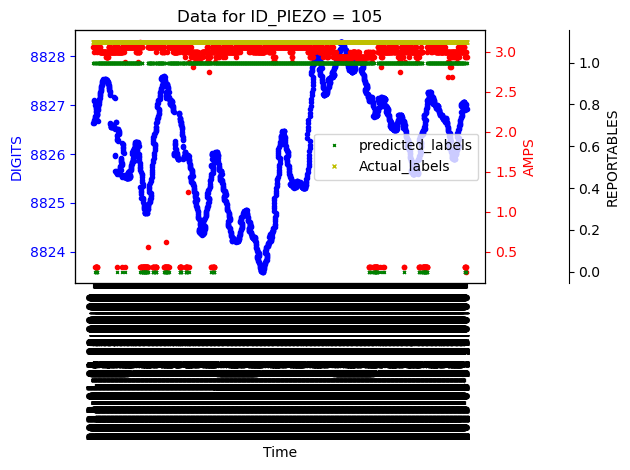

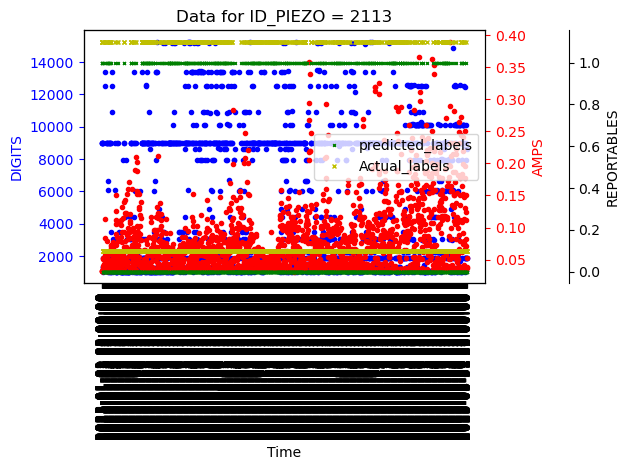

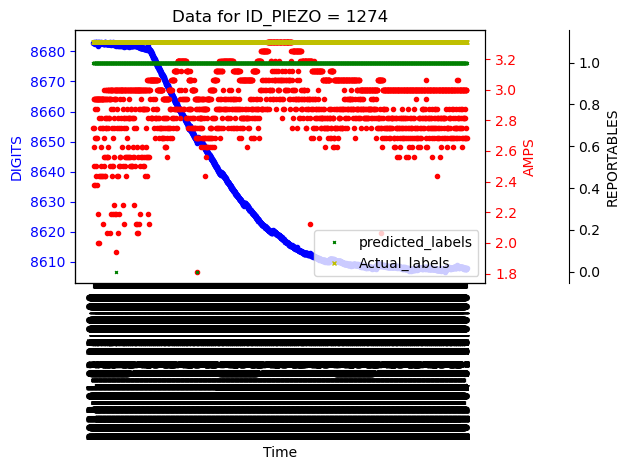

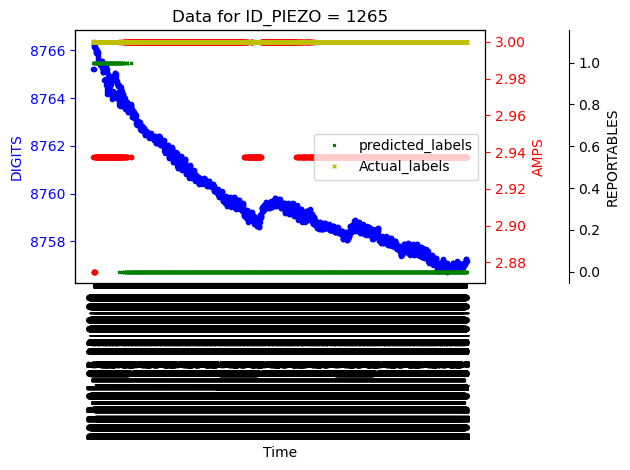

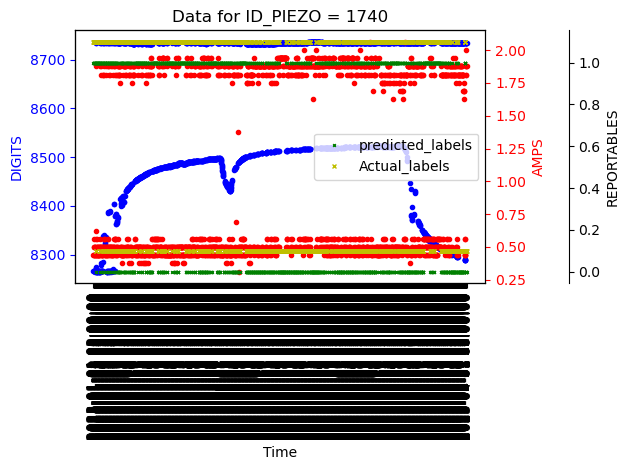

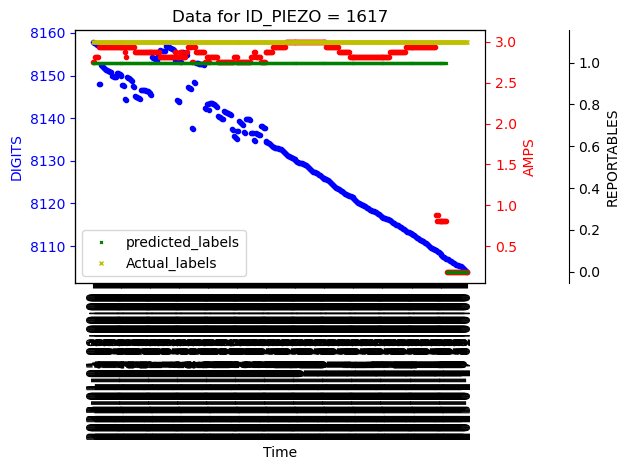

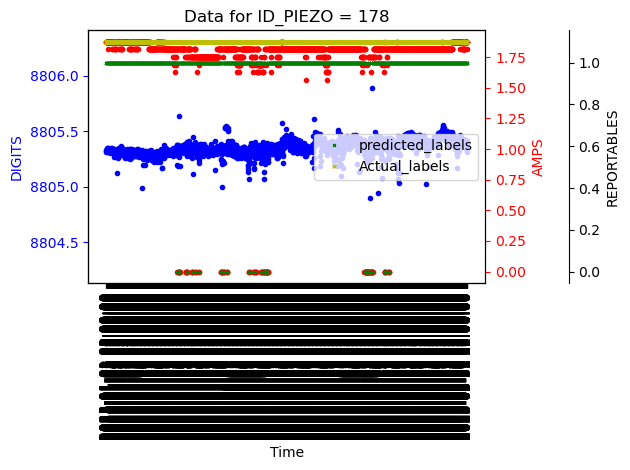

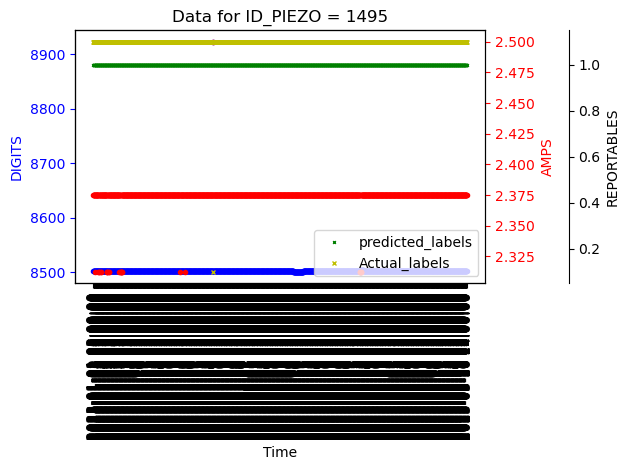

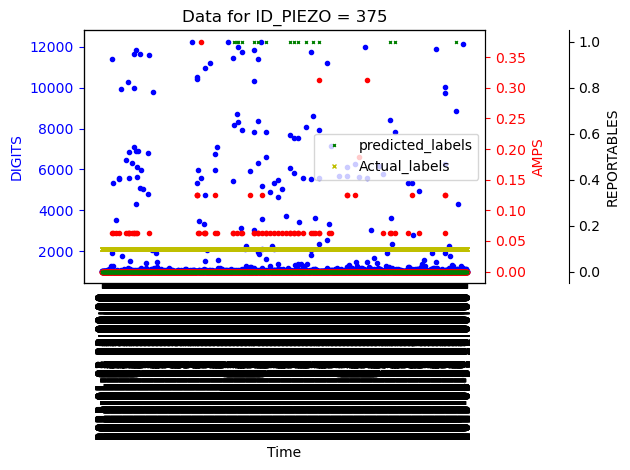

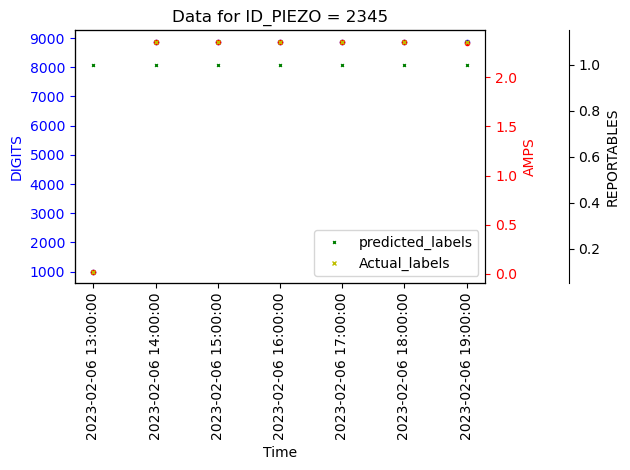

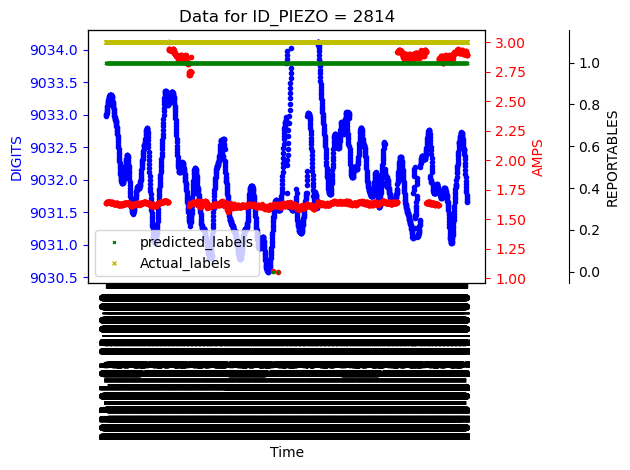

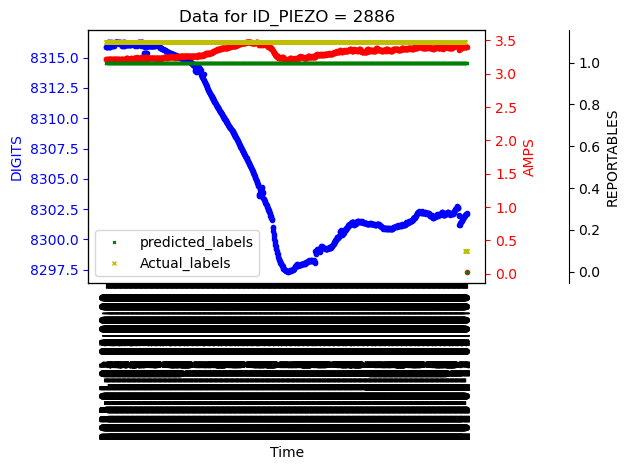

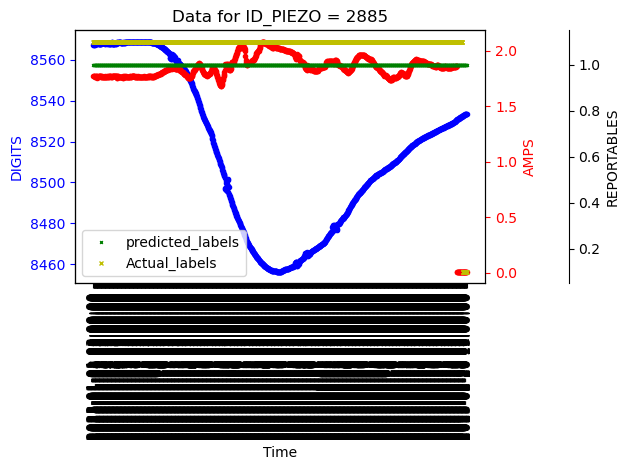

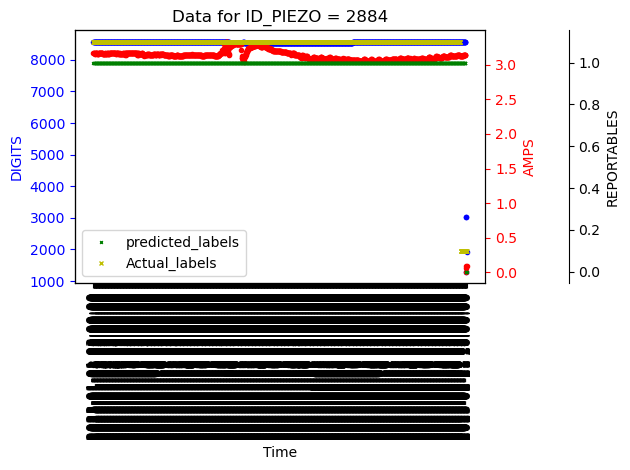

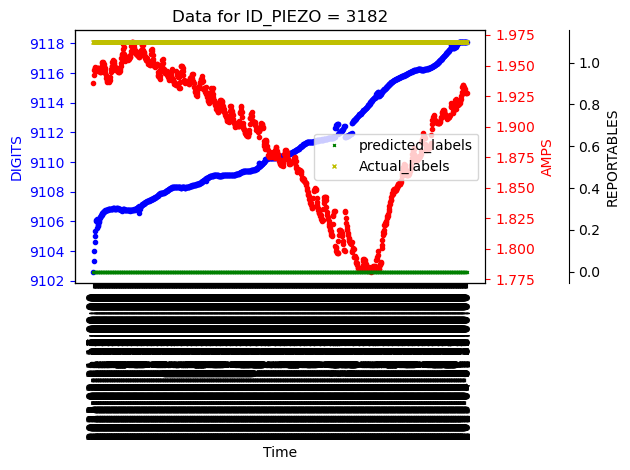

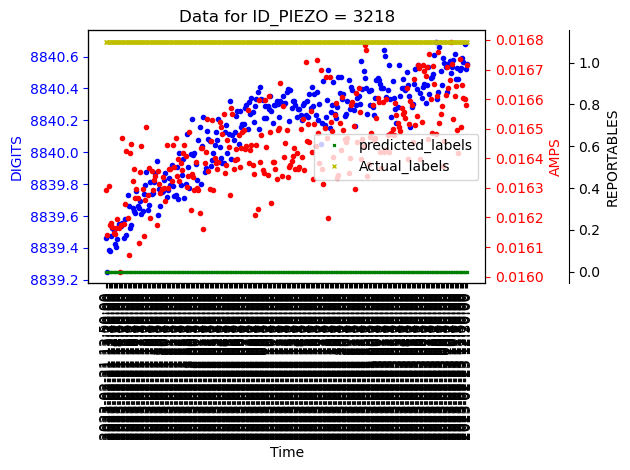

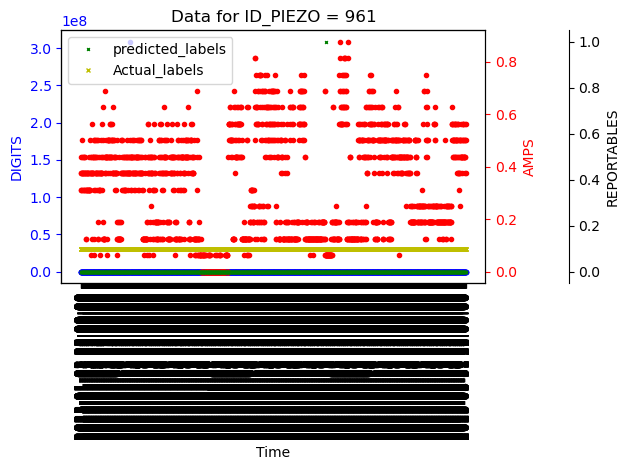

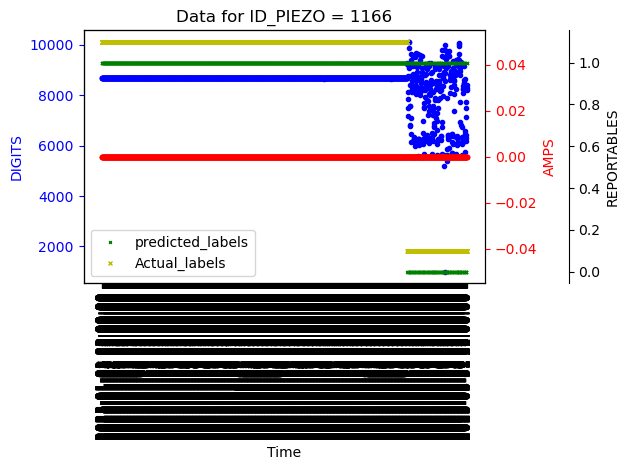

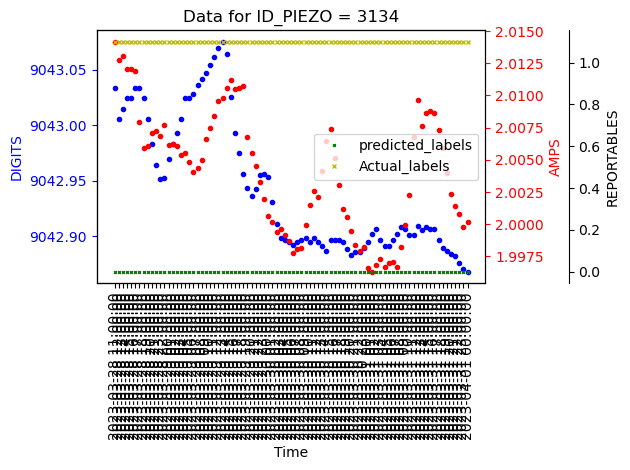

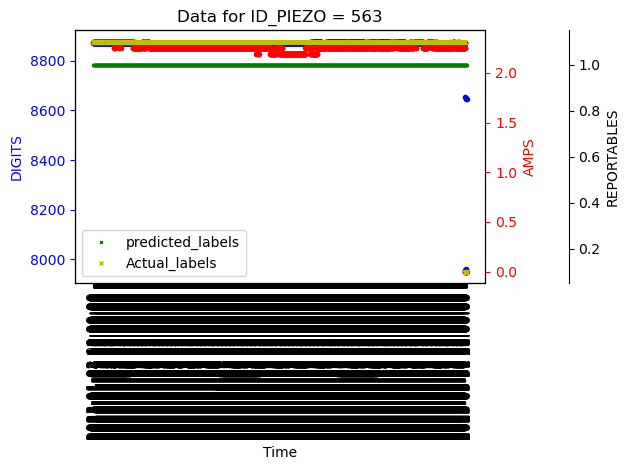

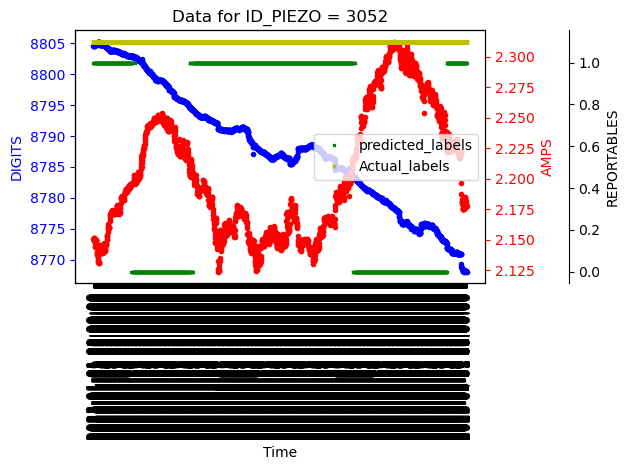

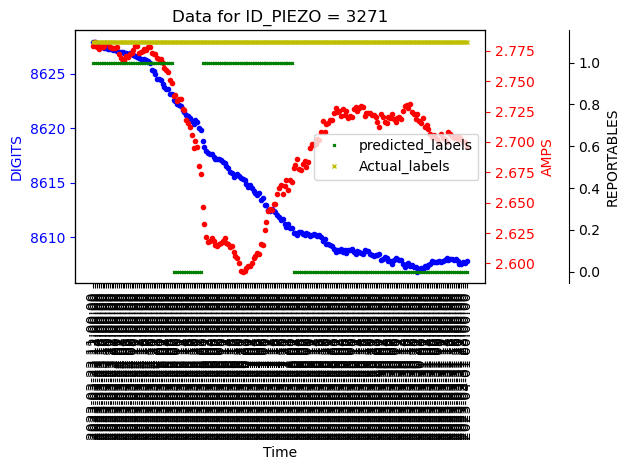

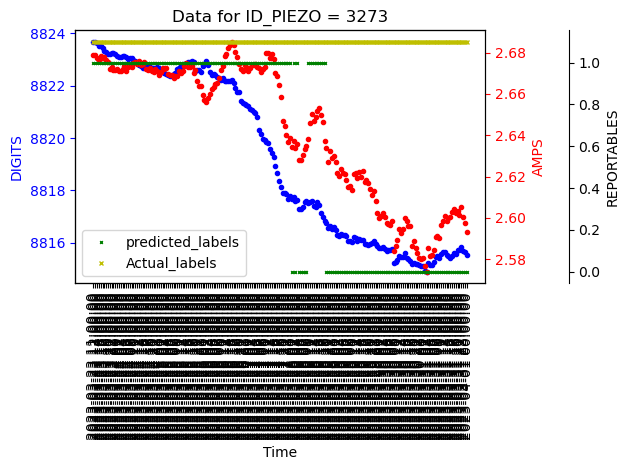

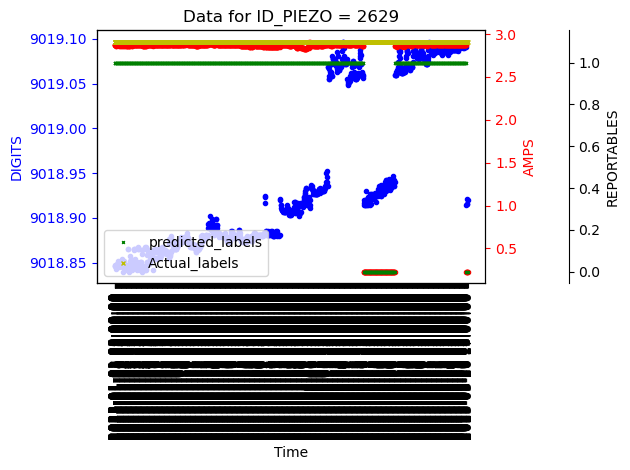

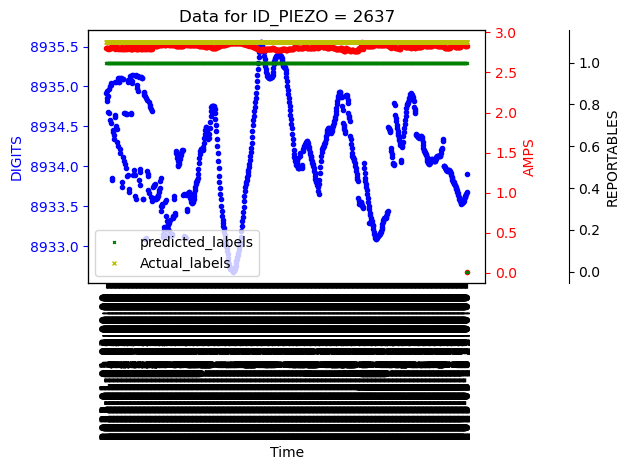

In [38]:
import matplotlib.pyplot as plt

val1['REPORTABLE']=val1['REPORTABLE']+0.1

# Filter the dataframe

filtered_df = val1[val1['COMPARE'] == False]

 

# Get the unique 'ID_PIEZO' values

unique_ids = filtered_df['ID_PIEZO'].unique()



# Plot data for each unique 'ID_PIEZO'

for id in unique_ids:

    # Filter dataframe for the current 'ID_PIEZO'

    df_id = val1[val1['ID_PIEZO'] == id]
 

    # Create a new figure and two subplots, sharing x-axis

    fig, ax1 = plt.subplots()

 

    # First subplot for 'X' values

    ax1.plot(df_id['TM_STAMP'], df_id['DIGITS'], 'bo', markersize=3)

    ax1.set_xlabel('Time')
    plt.xticks(rotation=90)

    # Make the y-axis label and line color blue to match the line color.

    ax1.set_ylabel('DIGITS', color='b')

    ax1.tick_params('y', colors='b')

 
    # Second subplot for 'Y' values, sharing the same x-axis

    ax2 = ax1.twinx()

    ax2.plot(df_id['TM_STAMP'], df_id['AMP'], 'ro', markersize=3)

    # Make the y-axis label and line color red to match the line color.

    ax2.set_ylabel('AMPS', color='r')

    ax2.tick_params('y', colors='r')
    
    # Create a third axis sharing the same x-axis
    ax3 = ax1.twinx()
    #ax4 = ax2.twinx()

    # Offset the third axis
    ax3.spines['right'].set_position(('outward', 60))
    #ax4.spines['left'].set_position(('outward', 50))

    # Plot data on the third axis
    ax3.plot(df_id['TM_STAMP'],df_id['PREDICTIONS'],'gx', markersize=2, label='predicted_labels')
    ax3.plot(df_id['TM_STAMP'],df_id['REPORTABLE'],'yx', markersize=3, label='Actual_labels')
    ax3.set_ylabel('REPORTABLES', color='black')
    ax3.tick_params('y', colors='black')
    
    # Plot data on the fourth axis
    #ax4.plot(df_id['TM_STAMP'],df_id['SIG2NOISE'], c='black', marker='o', markersize=2, label='sig2noise')
    #ax4.set_ylabel('sig2noise')
    #ax4.tick_params('y')
    
    # Add a legend
    lines = ax3.get_lines()
    ax3.legend(lines, [line.get_label() for line in lines])
    # Add a title to the plot

    plt.title(f"Data for ID_PIEZO = {id}")


    fig.tight_layout()  # This ensures the right y-label is not cut off
    


    plt.show()
    #
    fig.savefig('C:\Temp\ML_FIGURES_14\{0}.png'.format(id), bbox_inches='tight',dpi=300)